In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="crest")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "pdf.fonttype": 42})
pd.set_option("display.max_columns", None)

In [2]:
ROOT = Path("..").resolve()
RESULTS = ROOT / "results"

RUNS = {
    "Base": RESULTS / "base",
    "SFT 6k": RESULTS / "sft-6k",
    "Repetition E8": RESULTS / "sft-6k-repetition-epoch-8",
    "Repetition E16": RESULTS / "sft-6k-repetition-epoch-16",
}

benchmarks = {
    "minerva_math_500::hamish_zs_reasoning": "MATH-500",
    "aime:2024::olmo3:adapt": "AIME 2024",
    "aime:2025::olmo3:adapt": "AIME 2025",
}

FOCUS = ["SFT 6k", "Repetition E16"]
COLORS = dict(zip(RUNS, sns.color_palette("crest", len(RUNS))))

In [3]:
def last_box(text):
    matches = list(re.finditer(r"\\(?:boxed|fbox)\s*\{", text))
    if matches:
        start, depth = matches[-1].end(), 1
        for i in range(start, len(text)):
            depth += (text[i] == "{") - (text[i] == "}")
            if depth == 0:
                return text[start:i].strip()
    return ""


def repeated_spans(text):
    words = text.lower().split()
    spans = list(zip(*(words[i:] for i in range(10))))
    return 1 - len(set(spans)) / len(spans) if spans else 0.0

In [45]:
rows, caps, reference = [], {}, {}

for run, directory in RUNS.items():
    for path in directory.rglob("*-predictions.jsonl"):
        metrics_path = path.with_name(path.name.replace("-predictions.jsonl", "-metrics.json"))
        meta = json.loads(metrics_path.read_text())
        cfg, model = meta["task_config"], meta["model_config"]
        task = cfg["metadata"]["alias"]
        if task not in benchmarks:
            continue
        benchmark = benchmarks[task]
        records = [json.loads(line) for line in path.read_text().splitlines()]

        # OLMES auto-batching uses the longest prompt's remaining context budget.
        gen = cfg["generation_kwargs"]
        max_prompt = max(o["context_tokens"] for r in records for o in r["model_output"])
        cap = min(gen["max_gen_toks"], model["max_length"] - max_prompt)
        assert meta["compute_config"]["batch_size"] == "auto"
        settings = (cfg, meta["task_hash"], model["max_length"], model["tokenizer"], cap)
        if run == "Base":
            reference[benchmark] = settings
        assert settings == reference[benchmark]
        caps[benchmark] = cap

        task_scores = []
        for record in records:
            scores = []
            for output in record["model_output"]:
                if benchmark.startswith("AIME"):
                    correct = any(a.strip() == record["label"].strip() for a in output["model_answer"])
                else:
                    correct = bool(record["metrics"]["exact_match_flex"])
                scores.append(correct)
                text = output["continuation"]
                final = text.rsplit("</think>", 1)[-1] if "</think>" in text else ""
                assert output["num_tokens"] <= cap
                rows.append({
                    "benchmark": benchmark, "run": run, "problem": record["native_id"],
                    "tokens": output["num_tokens"], "complete": output["num_tokens"] < cap,
                    "answered": bool(last_box(text)), "final_answer": bool(last_box(final)),
                    "correct": correct, "repeated": repeated_spans(text),
                })
            assert len(scores) == gen.get("repeats", 1)
            if benchmark.startswith("AIME"):
                assert np.isclose(np.mean(scores), record["metrics"]["pass_at_1"])
            task_scores.extend(scores)
        assert np.isclose(np.mean(task_scores), meta["metrics"]["primary_score"])

df = pd.DataFrame(rows)
df["answered_correct"] = df.answered & df.correct
print(f"{len(df):,} responses")

3,920 responses


## Completion, answers and accuracy

Completion = below the effective cap: **31,942 tokens on MATH-500; 16,384 on AIME**.

Answer = complete, nonempty last `\boxed{}` / `\fbox{}`

In [47]:
summary = df.groupby(["benchmark", "run"], sort=False).agg(
    N=("correct", "size"), complete=("complete", "mean"), tokens=("tokens", "mean"),
    answered=("answered", "sum"), correct=("correct", "sum"),
    answered_correct=("answered_correct", "sum"), repeated=("repeated", "mean"))

summary = summary.reindex([(benchmark, run) for benchmark in benchmarks.values() for run in RUNS])
metrics = pd.DataFrame({
    "N": summary.N,
    "Complete (%)": summary.complete * 100,
    "Mean tokens": summary.tokens,
    "Answer (%)": summary.answered / summary.N * 100,
    "Acc. | answer (%)": summary.answered_correct / summary.answered * 100,
    "Acc. | all (%)": summary.correct / summary.N * 100,
})

metrics.round(1)

N  Complete (%)  Mean tokens  Answer (%)  \
benchmark run                                                          
MATH-500  Base            500         100.0       2175.8        73.2   
          SFT 6k          500          97.8       6374.6        98.2   
          Repetition E8   500          99.4       5496.0        99.6   
          Repetition E16  500          99.6       5382.2        99.6   
AIME 2024 Base            240          98.3       4110.5        12.5   
          SFT 6k          240          36.7      13842.7        39.2   
          Repetition E8   240          55.0      12747.5        60.0   
          Repetition E16  240          52.5      12838.6        56.7   
AIME 2025 Base            240          95.8       4370.0        16.2   
          SFT 6k          240          34.2      13825.7        35.4   
          Repetition E8   240          45.0      13580.3        49.2   
          Repetition E16  240          47.9      13373.2        50.8   

                          Acc. | answer (%)  Acc. | all (%)  
benchmark run                                                
MATH-500  Base                         85.5            63.0  
          SFT 6k                       90.0            88.4  
          Repetition E8                91.2            90.8  
          Repetition E16               91.4            91.0  
AIME 2024 Base                         80.0            10.0  
          SFT 6k                       75.5            29.6  
          Repetition E8                80.6            48.3  
          Repetition E16               79.4            45.0  
AIME 2025 Base                         92.3            15.0  
          SFT 6k                       74.1            26.2  
          Repetition E8                60.2            29.6  
          Repetition E16               63.9            32.5

## Answer outcomes

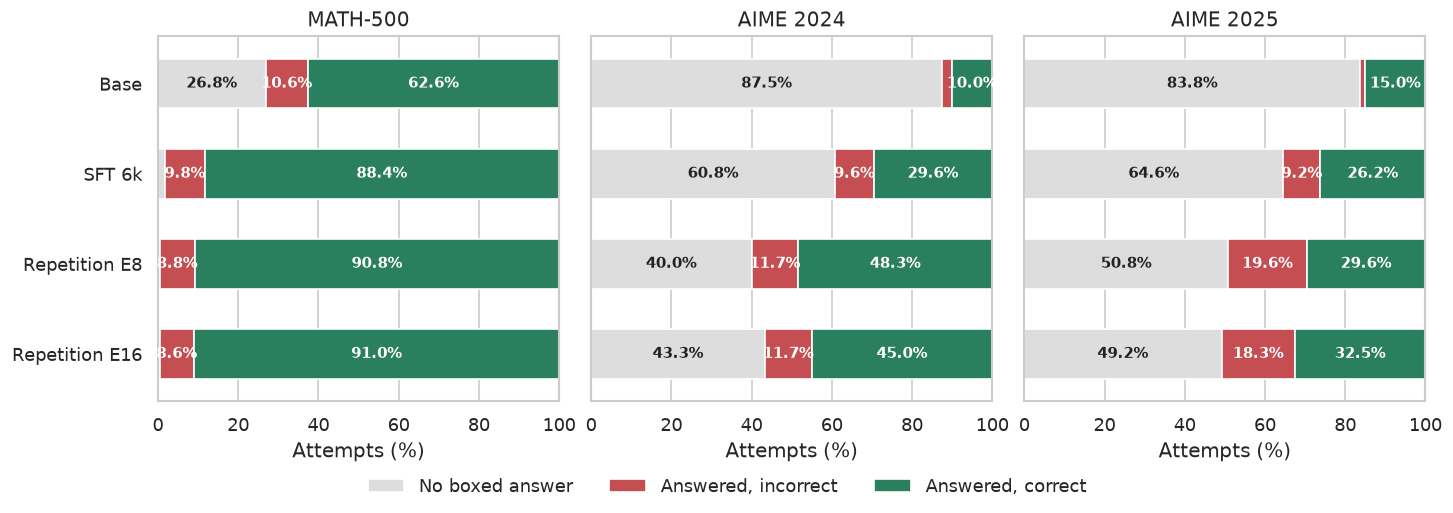

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharex=True, sharey=True, layout="constrained")
colors = ["#dddddd", "#c44e52", "#2a7f5f"]
for ax, benchmark in zip(axes, benchmarks.values()):
    g = summary.loc[benchmark].reindex(RUNS)
    outcomes = pd.DataFrame({
        "No boxed answer": (g.N - g.answered) / g.N * 100,
        "Answered, incorrect": (g.answered - g.answered_correct) / g.N * 100,
        "Answered, correct": g.answered_correct / g.N * 100,
    })

    outcomes.plot.barh(stacked=True, ax=ax, color=colors, width=.55, legend=False)
    for container, color in zip(ax.containers, colors):
        ax.bar_label(container, labels=[f"{b.get_width():.1f}%" if b.get_width() >= 6 else ""
                                      for b in container], label_type="center", fontsize=9, weight="bold",
                     color="#222222" if color == colors[0] else "white")

    ax.set(title=benchmark, xlabel="Attempts (%)", ylabel="", xlim=(0, 100))
    ax.grid(axis="y", visible=False)

axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3, frameon=False)
plt.show()

## Response length

6k vs E16. Jumps at the cap represent the model hitting the generation limit.

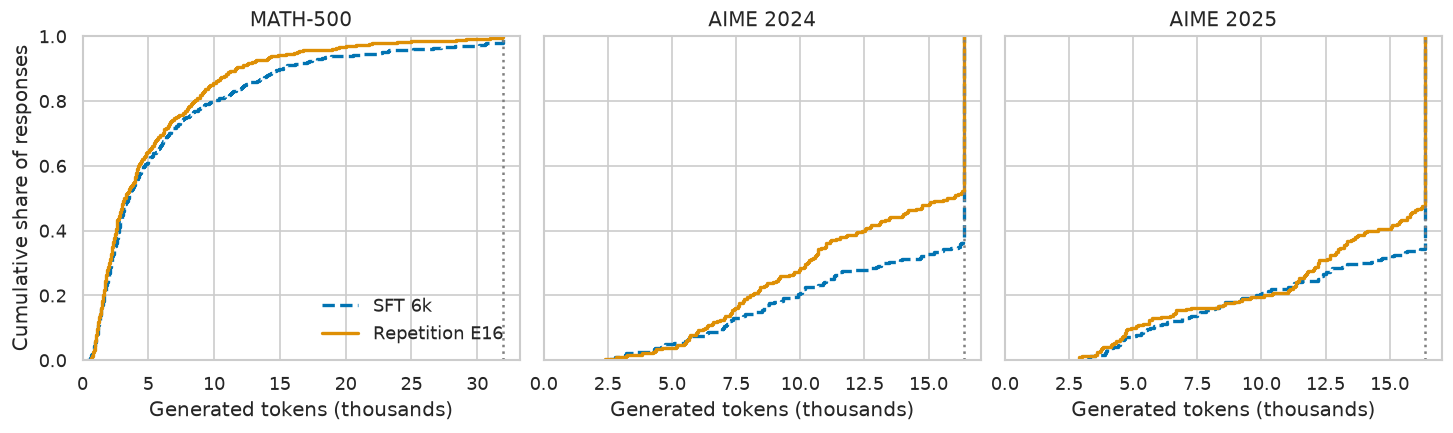

,,median,p90
benchmark,run,,
AIME 2024,Base,4008.0,4132.0
AIME 2025,Base,4018.0,4102.0
MATH-500,Base,1788.0,4086.0
AIME 2024,SFT 6k,16384.0,16384.0
AIME 2025,SFT 6k,16384.0,16384.0
MATH-500,SFT 6k,3474.0,15143.0
AIME 2024,Repetition E8,15012.0,16384.0
AIME 2025,Repetition E8,16384.0,16384.0
MATH-500,Repetition E8,3000.0,12333.0


In [49]:
length_colors = sns.color_palette("colorblind", len(FOCUS))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True, layout="constrained")
for ax, benchmark in zip(axes, benchmarks.values()):
    g = df[(df.benchmark == benchmark) & df.run.isin(FOCUS)].assign(tokens_k=lambda x: x.tokens / 1000)
    for run, color, style in zip(FOCUS, length_colors, ["--", "-"]):
        sns.ecdfplot(data=g[g.run == run], x="tokens_k", color=color,
                     linestyle=style, linewidth=2, label=run, ax=ax)
        
    cap = caps[benchmark] / 1000
    ax.axvline(cap, color="gray", linestyle=":")
    ax.set(title=benchmark, xlabel="Generated tokens (thousands)", xlim=(0, cap * 1.04))
    if ax is axes[0]:
        ax.legend(loc="lower right", frameon=False)
        
axes[0].set_ylabel("Cumulative share of responses")
plt.show()

df.groupby(["benchmark", "run"], sort=False).tokens.agg(
    median="median", p90=lambda x: x.quantile(.9)).round()

Base outputs cluster around 4k tokens despite a much higher generation limit, with some exceeding 4,096. This suggests thatthe model learned to terminate around that length during pretraining.

## Repetition

Mean share of overlapping ten-word spans that repeat an earlier identical span.

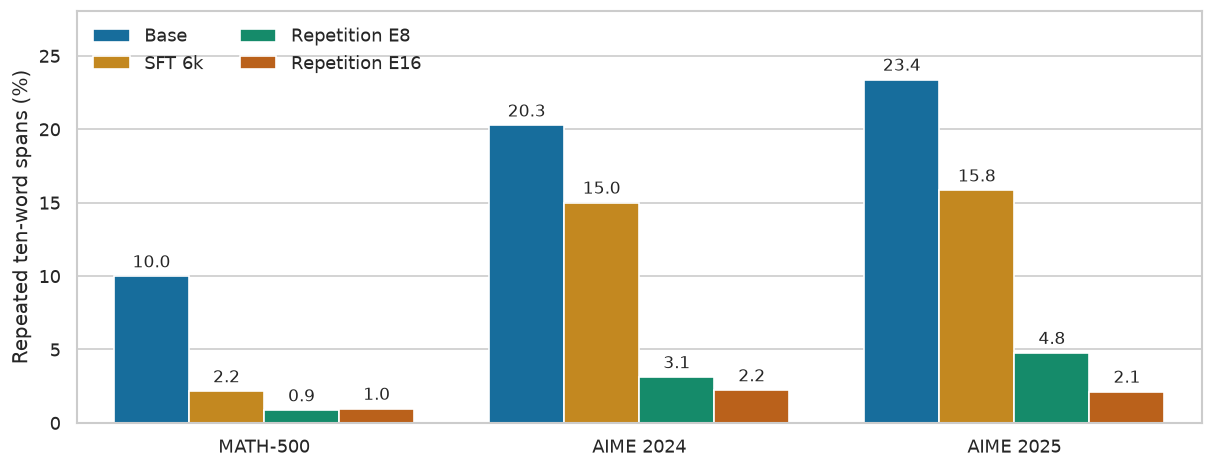

In [50]:
repetition = summary.reset_index().assign(repeated=lambda x: x.repeated * 100)
fig, ax = plt.subplots(figsize=(10, 3.8), layout="constrained")
sns.barplot(data=repetition, x="benchmark", y="repeated", hue="run",
            hue_order=list(RUNS), palette=COLORS, errorbar=None, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3, fontsize=10)
    
ax.set(xlabel="", ylabel="Repeated ten-word spans (%)", ylim=(0, repetition.repeated.max() * 1.2))
ax.legend(title="", frameon=False, ncol=2)
ax.grid(axis="x", visible=False)
plt.show()